# Attention-head pruning by head similarity

Accuracy and model size as the similarity threshold rises, for heads pruned by **linear CKA** and **angular distance** (`head_similarity_thresholds.py`).

A head is pruned when its similarity to an earlier kept head in the same layer is above the threshold, so a **lower threshold prunes more heads**. Threshold 1.0 is the full, unpruned model.

Data: `head_pruning_accuracies_imagenet1k.csv`, written by `collect_head_accuracies.py`. One figure per metric × model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ANALYSIS = Path(".")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})

df = pd.read_csv(ANALYSIS / "head_pruning_accuracies_imagenet1k.csv")

## Readable names

In [2]:
MODEL_NAMES = {
    "WinKawaks/vit-small-patch16-224": "ViT-Small",
    "facebook/deit-small-patch16-224": "DeiT-Small",
    "facebook/dinov2-base": "DINOv2-Base",
    "google/vit-large-patch16-224": "ViT-Large",
}
METRIC_NAMES = {"cka": "Linear CKA", "angdist": "Angular distance"}
DATASET_NAMES = {"imagenet-1k": "ImageNet-1k"}

# Fixed colour and marker per model (colour-blind-checked palette; markers so identity never
# relies on colour alone). Same order in every figure.
MODEL_ORDER = list(MODEL_NAMES.values())
COLOURS = dict(zip(MODEL_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
MARKERS = dict(zip(MODEL_ORDER, ["o", "s", "^", "D"]))

data = df.assign(
    Model=df.model.map(MODEL_NAMES),
    Metric=df.metric.map(METRIC_NAMES),
    Dataset=df.dataset.map(DATASET_NAMES),
    Accuracy=100 * df.accuracy_mean,
    AccuracyStd=100 * df.accuracy_std,
).rename(columns={
    "threshold": "Threshold",
    "heads_kept_pct": "Heads kept (%)",
    "total_heads_kept": "Heads kept",
    "total_heads": "Heads in full model",
    "params_saved_pct": "Encoder parameters saved (%)",
})
data.head()

,metric,Threshold,model,dataset,head_dict,accuracy_mean,accuracy_std,Heads kept,Heads in full model,Heads kept (%),params_saved,Encoder parameters saved (%),Model,Metric,Dataset,Accuracy,AccuracyStd
0,angdist,0.05,WinKawaks/vit-small-patch16-224,imagenet-1k,"{0: [0], 1: [0], 2: [0], 3: [0], 4: [0], 5: [0...",0.067733,0.002579,12,72,16.6667,5909760,27.7537,ViT-Small,Angular distance,ImageNet-1k,6.77333,0.257941
1,angdist,0.10,WinKawaks/vit-small-patch16-224,imagenet-1k,"{0: [0], 1: [0], 2: [0], 3: [0], 4: [0], 5: [0...",0.067733,0.002579,12,72,16.6667,5909760,27.7537,ViT-Small,Angular distance,ImageNet-1k,6.77333,0.257941
2,angdist,0.15,WinKawaks/vit-small-patch16-224,imagenet-1k,"{0: [0], 1: [0], 2: [0], 3: [0], 4: [0], 5: [0...",0.067733,0.002579,12,72,16.6667,5909760,27.7537,ViT-Small,Angular distance,ImageNet-1k,6.77333,0.257941
3,angdist,0.20,WinKawaks/vit-small-patch16-224,imagenet-1k,"{0: [0], 1: [0], 2: [0], 3: [0], 4: [0], 5: [0...",0.067733,0.002579,12,72,16.6667,5909760,27.7537,ViT-Small,Angular distance,ImageNet-1k,6.77333,0.257941
4,angdist,0.25,WinKawaks/vit-small-patch16-224,imagenet-1k,"{0: [0], 1: [0], 2: [0], 3: [0], 4: [0], 5: [0...",0.067733,0.002579,12,72,16.6667,5909760,27.7537,ViT-Small,Angular distance,ImageNet-1k,6.77333,0.257941


## Accuracy and heads lost vs threshold

One plot per metric × model. Left axis: top-1 accuracy, mean over 3 seeds with ± 1 std error bars (the std is small, 0.05–0.8 points, so the caps are short). Right axis: attention heads lost to pruning, out of the model's total. Lower thresholds prune more heads; 1.0 is the full model.

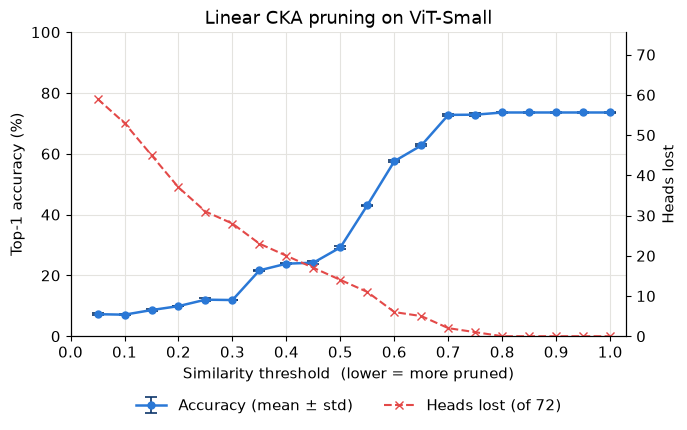

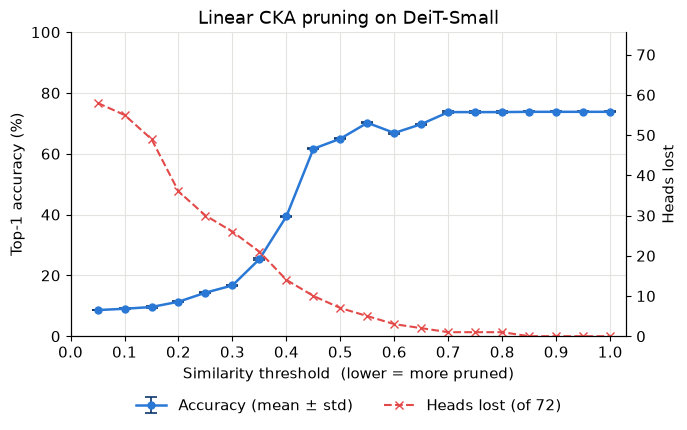

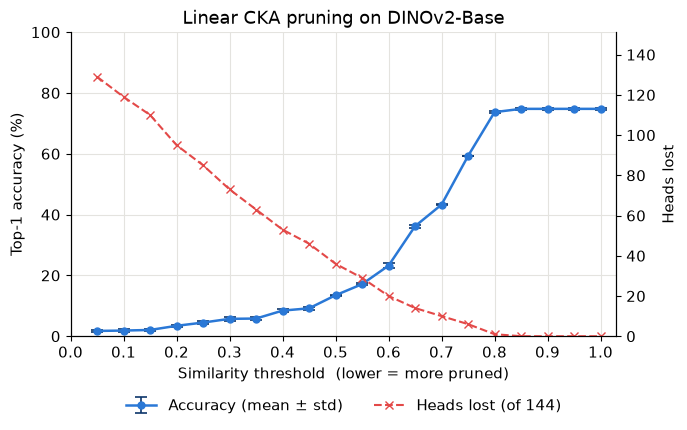

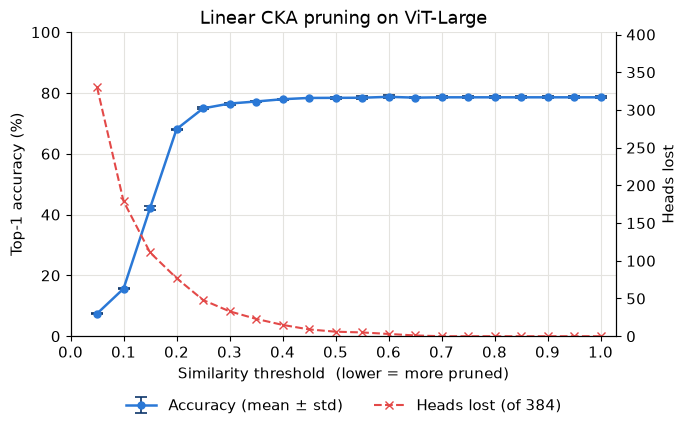

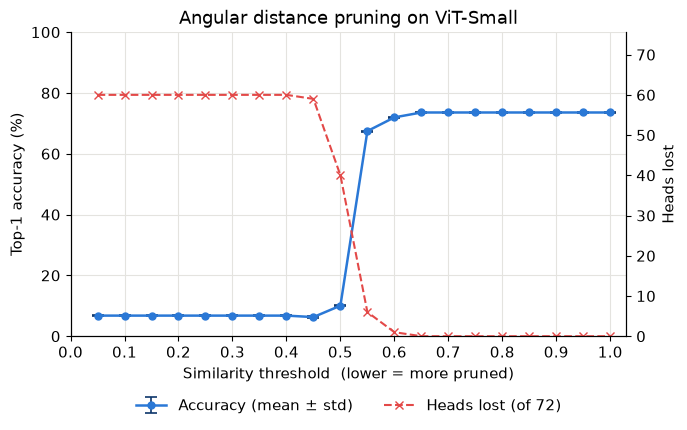

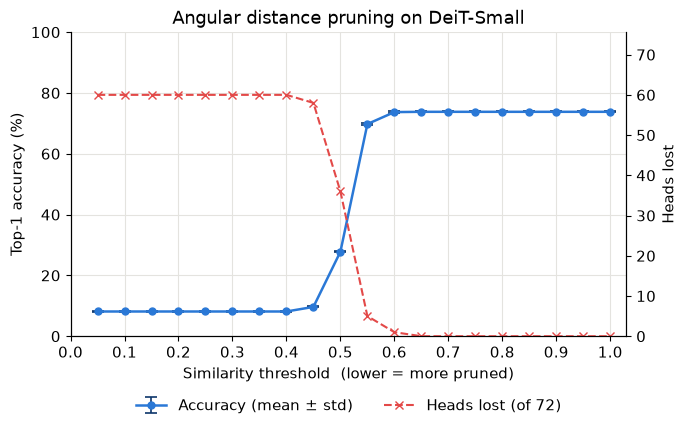

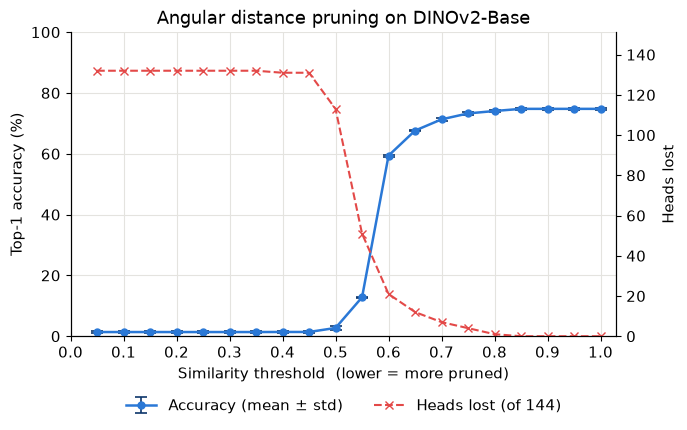

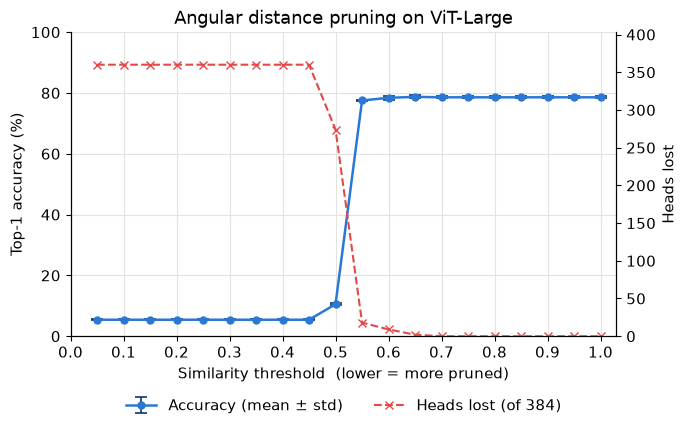

In [3]:
ACC_COLOUR = "#2a78d6"
HEADS_COLOUR = "#e34948"

data["Heads lost"] = data["Heads in full model"] - data["Heads kept"]

for metric in ["cka", "angdist"]:
    for model in MODEL_NAMES.keys():
        subset = data[(data.model == model) & (data.metric == metric)].sort_values("Threshold")
        total_heads = subset["Heads in full model"].iloc[0]

        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax_heads = ax.twinx()

        acc = ax.errorbar(
            subset["Threshold"], subset["Accuracy"], yerr=subset["AccuracyStd"],
            fmt="o-", color=ACC_COLOUR, markersize=5, linewidth=1.8,
            ecolor="#0d366b", elinewidth=1.2, capsize=4, capthick=1.2,
            label="Accuracy (mean ± std)", zorder=3,
        )
        heads, = ax_heads.plot(
            subset["Threshold"], subset["Heads lost"], "x--", color=HEADS_COLOUR,
            markersize=6, linewidth=1.5, label=f"Heads lost (of {total_heads})",
        )

        ax.set_title(f"{METRIC_NAMES[metric]} pruning on {MODEL_NAMES[model]}")
        ax.set_xlabel("Similarity threshold  (lower = more pruned)")
        ax.set_ylabel("Top-1 accuracy (%)")
        ax.set_ylim(0, 100)
        ax_heads.set_ylabel("Heads lost")
        ax_heads.set_ylim(0, total_heads * 1.05)
        ax.set_xticks([round(0.1 * i, 1) for i in range(0, 11)])
        ax.set_xlim(0, 1.03)
        ax.grid(True)
        ax.legend(handles=[acc, heads], loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)

        fig.tight_layout()
        slug = f"head_pruning_{metric}_{model.split('/')[-1]}_imagenet1k"
        fig.savefig(FIGURES / f"{slug}.png", dpi=200, bbox_inches="tight")
        plt.show()

## Metric pruning vs random pruning

Does choosing heads by similarity beat removing the same number of heads at random? The random baseline (`make_random_head_configs.py`) removes 2.5–75% of all heads uniformly at random, 3 draws per level, keeping at least one head per layer (as the metric rule does).

x: share of the model's heads removed. y: accuracy change from the full model, in points. Each metric point is one distinct set of heads; the grey line is the mean over the 3 random draws, and the band spans the lowest to highest draw. Every point is itself a mean over 3 training seeds (std < 1 pt).

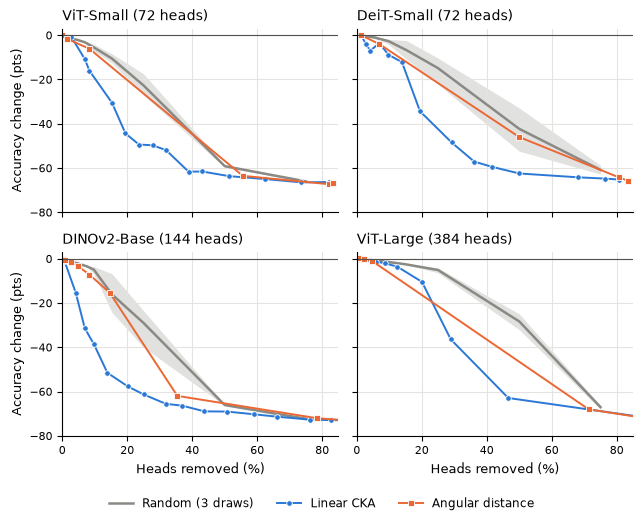

In [4]:
random = pd.read_csv(ANALYSIS / "head_pruning_random_imagenet1k.csv")
full_acc = data[data.Threshold == 1.0].groupby("model").Accuracy.first()

# Each distinct head_dict once (several thresholds can give the same one).
metric_pts = (data[data.Threshold < 1.0]
              .drop_duplicates(["model", "metric", "head_dict"])
              .assign(removed=lambda d: 100 - d["Heads kept (%)"]))
random_pts = random.assign(removed=100 - random.heads_kept_pct, Accuracy=100 * random.accuracy_mean)
random_lvl = (random_pts.groupby(["model", "removed"]).Accuracy
              .agg(["mean", "min", "max"]).reset_index())

METRIC_STYLE = {
    "cka": dict(color="#2a78d6", marker="o", label="Linear CKA"),
    "angdist": dict(color="#eb6834", marker="s", label="Angular distance"),
}
RANDOM_COLOUR = "#8a8984"

with plt.rc_context({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8.5,
                     "axes.spines.right": False}):
    fig, axes = plt.subplots(2, 2, figsize=(6.5, 5.2), sharex=True, sharey=True)
    for ax, model in zip(axes.flat, MODEL_NAMES):
        full = full_acc[model]
        r = random_lvl[random_lvl.model == model]
        # Random baseline: mean line + min-max band, anchored at the full model (0 removed).
        rx = [0] + list(r.removed)
        ax.fill_between(rx, [0] + list(r["min"] - full), [0] + list(r["max"] - full),
                        color=RANDOM_COLOUR, alpha=0.25, linewidth=0)
        ax.plot(rx, [0] + list(r["mean"] - full), color=RANDOM_COLOUR, linewidth=1.8,
                label="Random (3 draws)")
        for metric, style in METRIC_STYLE.items():
            m = metric_pts[(metric_pts.model == model) & (metric_pts.metric == metric)].sort_values("removed")
            ax.plot([0] + list(m.removed), [0] + list(m.Accuracy - full), linewidth=1.4,
                    markersize=4, markeredgecolor="white", markeredgewidth=0.6, **style)
        total = int(data.loc[data.model == model, "Heads in full model"].iloc[0])
        ax.set_title(f"{MODEL_NAMES[model]} ({total} heads)", loc="left")
        ax.axhline(0, color="#52514e", linewidth=0.8)
        ax.grid(True)
        ax.set_xlim(0, 85)
        ax.set_ylim(-80, 3)
    for ax in axes[1]:
        ax.set_xlabel("Heads removed (%)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Accuracy change (pts)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(FIGURES / "head_pruning_vs_random_imagenet1k.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURES / "head_pruning_vs_random_imagenet1k.pdf", bbox_inches="tight")
    plt.show()

### Metric minus random at the same number of heads removed

For every metric point, the random baseline's mean accuracy at the same % removed (interpolated between random levels), and the gap. Negative = the metric chose worse heads than chance.

In [5]:
import numpy as np

rows = []
for (model, metric), m in metric_pts.groupby(["model", "metric"], sort=False):
    r = random_lvl[random_lvl.model == model].sort_values("removed")
    rx = np.r_[0, r.removed]
    ry = np.r_[full_acc[model], r["mean"]]
    m = m[m.removed <= rx.max()]
    gap = m.Accuracy - np.interp(m.removed, rx, ry)
    rows.append({
        "Model": MODEL_NAMES[model], "Metric": METRIC_NAMES[metric],
        "Points": len(m),
        "Worse than random": int((gap < -1).sum()),
        "Within 1 pt": int((gap.abs() <= 1).sum()),
        "Better than random": int((gap > 1).sum()),
        "Mean gap (pts)": round(gap.mean(), 1),
        "Worst gap (pts)": round(gap.min(), 1),
    })
gaps = pd.DataFrame(rows)
gaps

,Model,Metric,Points,Worse than random,Within 1 pt,Better than random,Mean gap (pts),Worst gap (pts)
0,ViT-Small,Angular distance,4,2,2,0,-1.4,-2.8
1,ViT-Small,Linear CKA,15,11,4,0,-11.8,-28.6
2,DeiT-Small,Angular distance,4,2,2,0,-1.5,-3.7
3,DeiT-Small,Linear CKA,13,11,2,0,-12.5,-30.0
4,DINOv2-Base,Angular distance,7,3,4,0,-3.3,-17.5
5,DINOv2-Base,Linear CKA,14,12,2,0,-17.6,-38.2
6,ViT-Large,Angular distance,5,1,4,0,-1.3,-6.6
7,ViT-Large,Linear CKA,13,4,9,0,-5.7,-37.7


## Table view

The same numbers as the figures: for each model, the lowest threshold that keeps accuracy within 1 point of the full model, and how many heads it keeps there.

In [6]:
rows = []
for (metric, dataset, model), m in data.groupby(["Metric", "Dataset", "Model"], sort=False):
    full = m.loc[m.Threshold == 1.0, "Accuracy"].iloc[0]
    ok = m[m.Accuracy >= full - 1.0].sort_values("Threshold").iloc[0]
    rows.append({
        "Metric": metric, "Dataset": dataset, "Model": model,
        "Full-model accuracy (%)": round(full, 2),
        "Lowest threshold within 1 pt": ok.Threshold,
        "Accuracy there (%)": round(ok.Accuracy, 2),
        "Heads kept": f"{ok['Heads kept']} / {ok['Heads in full model']}",
        "Encoder parameters saved (%)": round(ok["Encoder parameters saved (%)"], 2),
    })
summary = pd.DataFrame(rows)
summary

,Metric,Dataset,Model,Full-model accuracy (%),Lowest threshold within 1 pt,Accuracy there (%),Heads kept,Encoder parameters saved (%)
0,Angular distance,ImageNet-1k,ViT-Small,73.57,0.65,73.57,72 / 72,0.00
1,Linear CKA,ImageNet-1k,ViT-Small,73.57,0.70,72.79,70 / 72,0.93
2,Angular distance,ImageNet-1k,DeiT-Small,73.79,0.60,73.70,71 / 72,0.46
3,Linear CKA,ImageNet-1k,DeiT-Small,73.79,0.70,73.70,71 / 72,0.46
4,Angular distance,ImageNet-1k,DINOv2-Base,74.77,0.80,74.06,143 / 144,0.23
5,Linear CKA,ImageNet-1k,DINOv2-Base,74.77,0.85,74.77,144 / 144,0.00
6,Angular distance,ImageNet-1k,ViT-Large,78.56,0.60,78.39,375 / 384,0.78
7,Linear CKA,ImageNet-1k,ViT-Large,78.56,0.40,77.94,369 / 384,1.30
